**Exploratory Data Analysis (EDA) for the UNSW-NB15 Dataset**

We decided to explore the dataset and prepare the feature transformations in this notebook. The goal is to select a total of 30,000 rows, which can be split into training and validation sets:
- Training set: 24,000 rows
- Validation set: 6,000 rows

Our task is **binary classification**: predict whether a network flow is an attack (`label = 1`) or normal traffic (`label = 0`). The column `attack_cat` (attack type) is never used as an input, because it gives away the label. We only use it for additional findings at the end of this notebook.

All exploration is done on the **training file only**. We load the test file to check its size, but we do not look into it, so the final test score stays honest.

**1. Setup**

In [62]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path("../data")
FIGS = Path("../figures")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

**2. Load the data**

The training file should have 175,341 rows and the testing file 82,332 rows, each with 45 columns. The files downloaded from Kaggle have their names swapped compared to the UNSW-NB15 paper, so we renamed them: `training_set` is now the 175,341-row file.

In [63]:
train = pd.read_csv(DATA / "UNSW_NB15_training_set.csv")
test  = pd.read_csv(DATA / "UNSW_NB15_testing_set.csv")
print("train:", train.shape, " test:", test.shape)
train.head()

train: (175341, 45)  test: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


**3. Column types**

We check the type of every column to know which ones need encoding (text) and which ones need scaling (numbers).

In [64]:
train.info() # Check the column types for transformation

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [65]:
DROP = ["id", "attack_cat", "label"] # id is a row number, attack_cat and label are targets, so none of them are inputs
cat_cols = train.drop(columns=DROP).select_dtypes(exclude="number").columns.tolist()
num_cols = train.drop(columns=DROP).select_dtypes(include="number").columns.tolist()
print(len(cat_cols), "categorical:", cat_cols)
print(len(num_cols), "numeric")

3 categorical: ['proto', 'service', 'state']
39 numeric


We have 3 categorical features (`proto`, `service`, `state`) and 39 numeric features, so 42 input features in total.

**4. Missing values and duplicates**

In [66]:
print("Missing values per column (non-zero only):")
print(train.isna().sum()[lambda s: s > 0])
print("\nservice value '-' count:", (train["service"] == "-").sum())

Missing values per column (non-zero only):
Series([], dtype: int64)

service value '-' count: 94168


There are no missing values. The `service` column uses `-` when no known service was detected. We treat `-` as its own category, not as a missing value.

In [67]:
feat_and_label = train.drop(columns=["id"])
n_dup = feat_and_label.duplicated().sum()
print(f"Exact duplicate rows (all columns except id): {n_dup:,} ({n_dup/len(train):.1%})")

features_only = train.drop(columns=DROP)
n_dup_feat = features_only.duplicated().sum()
print(f"Duplicate feature vectors (ignoring label): {n_dup_feat:,}")

# Check only (not removed): same features, different labels
conflict = features_only.assign(label=train["label"]).groupby(list(features_only.columns))["label"].nunique()
print("Feature vectors that appear with BOTH labels:", (conflict > 1).sum())

Exact duplicate rows (all columns except id): 67,601 (38.6%)
Duplicate feature vectors (ignoring label): 74,301
Feature vectors that appear with BOTH labels: 229


We counted exact duplicate rows of this dataset excluding the `id` column to see how many rows are actually duplicates (all features + label + attack type are the same).

The result is that there are 67,601 data points that share the exact same values. This comes from how the dataset is built: the attacks are synthetic and replayed, so the same attack produces the same flow record many times.

Our next step is to deduplicate the data by keeping only the first copy of each duplicate row. If we kept the duplicates, the same row could end up in both our training and validation sets, which would make the validation score look better than it really is.

We also found 229 feature vectors that appear with **both** labels, where the same traffic is labeled normal in one row and attack in another. These are not copies, so we keep them, however, no model can classify all of them correctly, but they are a very small share of the data so we think these should only be some natural occuring outliers.

In [68]:
train_dedup = train.drop_duplicates(subset=[c for c in train.columns if c != "id"])
print("before:", len(train), "| after:", len(train_dedup), "| removed:", len(train) - len(train_dedup))
print("exact duplicates left:", train_dedup.drop(columns=["id"]).duplicated().sum()) 

before: 175341 | after: 107740 | removed: 67601
exact duplicates left: 0


From here on, we use `train_dedup` for everything, because this is the data our models will be trained on.

**Why do we do this?**: It is important to remove them as we do not want to have identical data points shared between training and evaluation set as we do not want the model to remember the duplicated case without understanding why/how features affect the prediction ---> Avoiding leakage 

**5. Class balance**

We compare the share of normal vs attack rows before and after removing duplicates, since deduplicating can change the balance.

        before dedup  after dedup
label                            
Attack         0.681        0.518
Normal         0.319        0.482


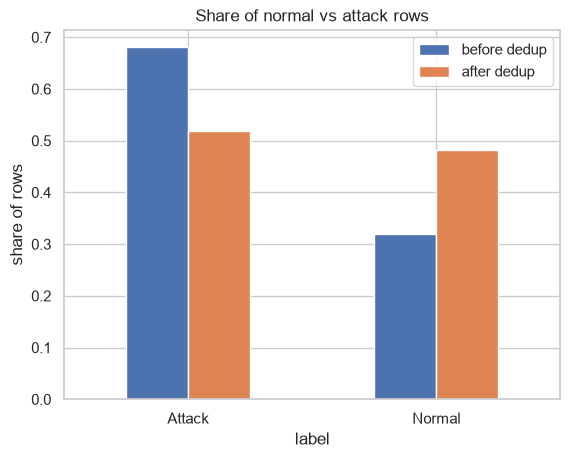

In [69]:
balance = pd.DataFrame({"before dedup": train["label"].value_counts(normalize=True), "after dedup": train_dedup["label"].value_counts(normalize=True)}).rename(index={0: "Normal", 1: "Attack"})
print(balance.round(3))

balance.plot.bar(rot=0, title="Share of normal vs attack rows")
plt.ylabel("share of rows")
plt.savefig(FIGS / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

Attacks are the majority in this dataset, but real networks carry mostly normal traffic. Nevertheless, after remove dedup the proportion of Attack label is still the majority with 51.8% compared to 48.2% of normal network actiity. The reason is that the duplication are made from the data generation/replayed attack of the author who made the dataset, and removing duplications mean removing mostly the duplicated attack cases. By doing this, we can have a more balanced dataset without needing for class weights or resampling.

Real networks, however, carry mostly normal traffic. A model trained and tested at around 50% attacks will look more precise here than it would in deployment, where false alarms would make up a larger share of its alerts. This is why we have to evaluate with precision, recall, F1 and false positive rate, not accuracy alone.


**6. Categorical features**

We check how many values each categorical feature has. Features with many rare values would create many one-hot columns, so we may group the rare ones into "other".

In [70]:
for c in cat_cols:
    print(f"\n{c}: {train_dedup[c].nunique()} unique values")
    print(train_dedup[c].value_counts().head(10))


proto: 133 unique values
proto
tcp     76293
udp     23027
unas     2582
ospf      775
arp       633
sctp      316
any        93
gre        63
rsvp       62
ipv6       59
Name: count, dtype: int64

service: 13 unique values
service
-           64951
http        18135
dns         11046
smtp         5025
ftp-data     3282
ftp          2691
ssh          1295
pop3         1104
snmp           63
ssl            56
Name: count, dtype: int64

state: 9 unique values
state
FIN    74478
INT    19726
CON    12487
REQ      953
RST       83
ECO       10
PAR        1
URN        1
no         1
Name: count, dtype: int64


`proto` has many values, but most of them are rare. We check how much of the data the most common values cover, to decide how many to keep.

In [71]:
vc = train_dedup["proto"].value_counts(normalize=True)
for k in [3, 5, 8, 10, 15]:
    print(f"top {k:>2} proto values cover {vc.head(k).sum():.1%} of rows")

top  3 proto values cover 94.6% of rows
top  5 proto values cover 95.9% of rows
top  8 proto values cover 96.3% of rows
top 10 proto values cover 96.4% of rows
top 15 proto values cover 96.7% of rows


In [72]:
TOP_PROTO = vc.head(15).index.tolist() # keep the 15 most common protocols, group the rest into "other"
outside = train_dedup[~train_dedup["proto"].isin(TOP_PROTO)]
print("kept:", TOP_PROTO)
print(f"rows outside top 15: {len(outside):,} ({len(outside)/len(train_dedup):.1%}), attack rate: {outside['label'].mean():.1%}")

kept: ['tcp', 'udp', 'unas', 'ospf', 'arp', 'sctp', 'any', 'gre', 'rsvp', 'ipv6', 'sun-nd', 'swipe', 'sep', 'mobile', 'pim']
rows outside top 15: 3,552 (3.3%), attack rate: 99.1%


We keep the top 15 `proto` values (96.7% of rows) and group the other 118 into "other" (3,552 rows, 99.1% attack).

**Why do we do this?**: One-hot encoding all 133 values would add 133 mostly-empty columns, and the rare protocols have too few rows to learn from. With top 15 + "other" we only add 16 columns, and the model still learns that an unusual protocol is suspicious ---> Fewer columns, same signal

Next, we look at the attack rate for each category. A category that is almost 100% attack (or 100% normal) is easy to classify

In [73]:
for c in cat_cols:
    rate = train_dedup.groupby(c)["label"].agg(["count", "mean"]).rename(columns={"mean": "attack_rate"})
    print(rate.sort_values("count", ascending=False).head(10).round(3), "\n")

       count  attack_rate
proto                    
tcp    76293        0.500
udp    23027        0.435
unas    2582        1.000
ospf     775        0.921
arp      633        0.000
sctp     316        1.000
any       93        1.000
gre       63        1.000
rsvp      62        1.000
ipv6      59        1.000 

          count  attack_rate
service                     
-         64951        0.495
http      18135        0.715
dns       11046        0.338
smtp       5025        0.687
ftp-data   3282        0.222
ftp        2691        0.549
ssh        1295        0.008
pop3       1104        0.996
snmp         63        0.984
ssl          56        1.000 

       count  attack_rate
state                    
FIN    74478        0.510
INT    19726        0.860
CON    12487        0.048
REQ      953        0.318
RST       83        0.145
ECO       10        0.000
PAR        1        0.000
URN        1        0.000
no         1        0.000 



Many categories are almost 100% attack or 100% normal. We keep all of them, but have some reasoning if they make sense from a networking point of view:
- **Makes sense:** `INT` (no reply, 86% attack) fits scans and floods, `CON` (two-way connection, 4.8% attack) fits normal traffic, and `http`/`smtp`/`ftp` are common exploit targets.
- **Likely lab artifact:** rare protocols like `unas` and `sctp` (100% attack), `pop3` (99.6% attack) and `arp` (0% attack) depend on how the lab generated traffic, not on real attack behavior.
- **Effect of dedup:** `dns` dropped from 84.2% to 33.8% attack, since many replayed attacks were DNS flows.

We also group the rare `state` values (`ECO`, `PAR`, `URN`, `no`, 13 rows) into "other". We cannot fully verify these patterns with this dataset alone ---> the validation-vs-test gap later will show if they carry over to new traffic.

**7. Skewed numeric features**

Network traffic features like byte counts often have a few huge values and many small ones (heavy right skew). This hurts models like logistic regression and SVM, so we check the skew of every numeric feature. `min_ge_0` tells us whether `log1p` is safe to apply (it needs values of 0 or more).

In [74]:
desc = train_dedup[num_cols].describe().T
desc["skew"] = train_dedup[num_cols].skew()
desc["min_ge_0"] = desc["min"] >= 0
desc.sort_values("skew", ascending=False).round(2)

,count,mean,std,min,25%,50%,75%,max,skew,min_ge_0
trans_depth,107740.0,1.700000e-01,9.800000e-01,0.0,0.00,0.000000e+00,0.000000e+00,1.720000e+02,136.44,True
response_body_len,107740.0,3.442630e+03,6.895163e+04,0.0,0.00,0.000000e+00,0.000000e+00,6.558056e+06,60.27,True
sbytes,107740.0,1.382541e+04,2.226348e+05,28.0,501.50,9.520000e+02,2.542000e+03,1.296523e+07,35.59,True
sloss,107740.0,7.900000e+00,8.404000e+01,0.0,0.00,2.000000e+00,6.000000e+00,4.803000e+03,35.18,True
dloss,107740.0,1.101000e+01,6.543000e+01,0.0,0.00,1.000000e+00,6.000000e+00,5.484000e+03,33.64,True
dbytes,107740.0,2.373248e+04,1.786209e+05,0.0,178.00,3.540000e+02,3.080000e+03,1.465555e+07,32.13,True
spkts,107740.0,3.019000e+01,1.734200e+02,1.0,4.00,1.000000e+01,2.200000e+01,9.616000e+03,32.01,True
dpkts,107740.0,3.006000e+01,1.365500e+02,0.0,2.00,8.000000e+00,1.800000e+01,1.097400e+04,30.01,True
dinpkt,107740.0,1.062900e+02,1.089290e+03,0.0,0.01,1.262000e+01,8.162000e+01,5.671682e+04,29.98,True
djit,107740.0,8.228200e+02,4.806700e+03,0.0,0.00,6.246000e+01,1.836300e+02,2.893883e+05,26.94,True


We plot six of the most important flow features before and after `log1p`.

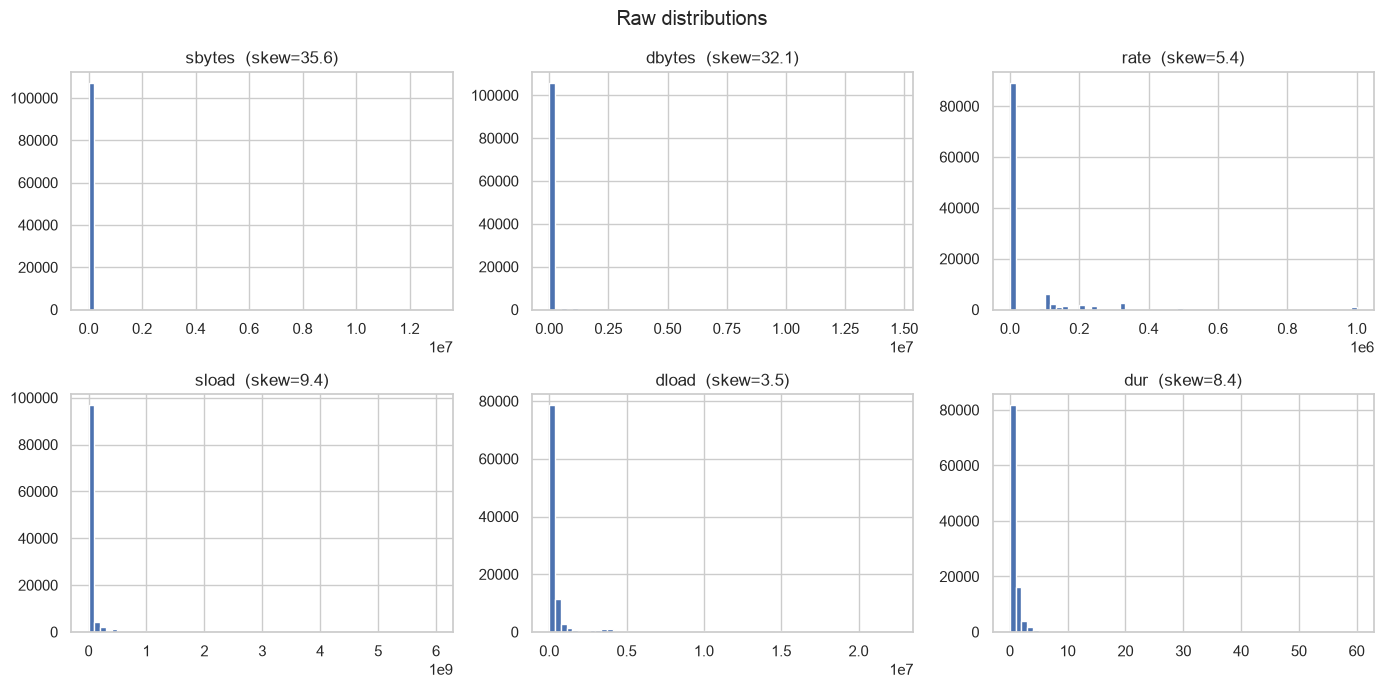

In [75]:
skew_feats = ["sbytes", "dbytes", "rate", "sload", "dload", "dur"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, skew_feats):
    ax.hist(train_dedup[c], bins=60)
    ax.set_title(f"{c}  (skew={train_dedup[c].skew():.1f})")
plt.suptitle("Raw distributions")
plt.tight_layout()
plt.savefig(FIGS / "hist_raw.png", dpi=150)
plt.show()

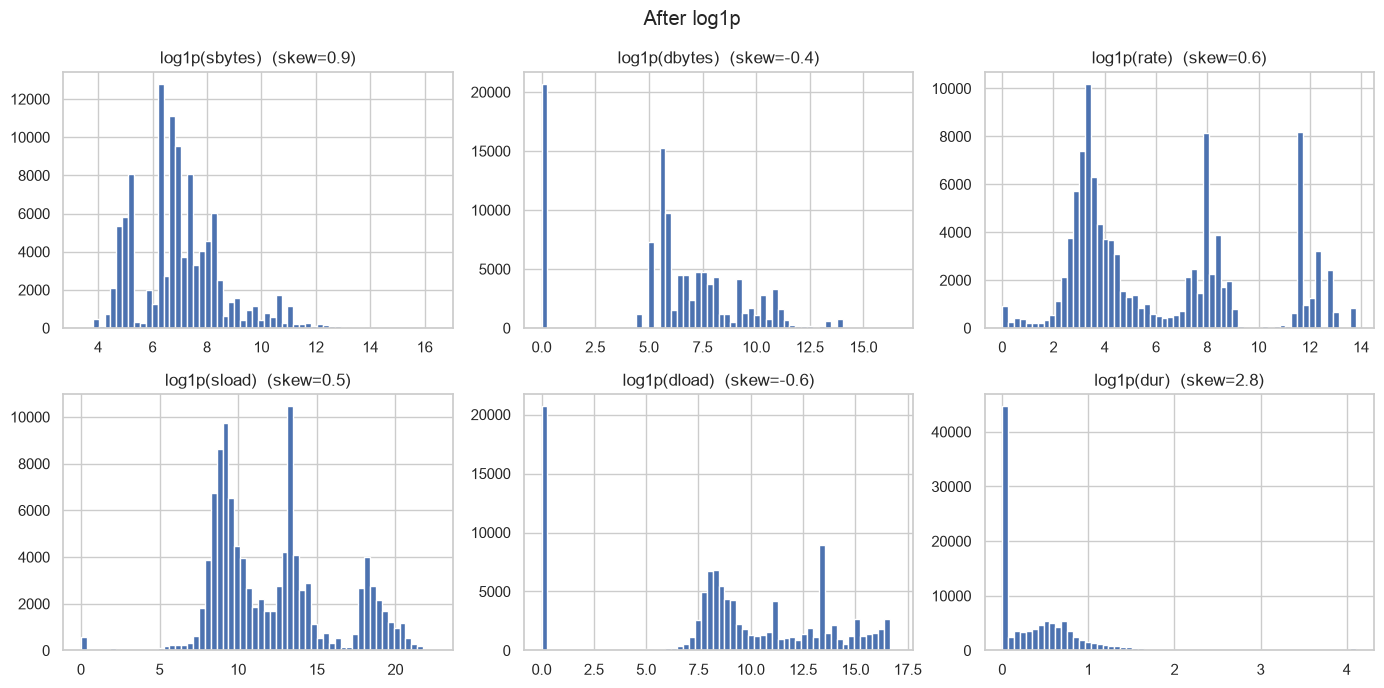

In [76]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, skew_feats):
    x = np.log1p(train_dedup[c])
    ax.hist(x, bins=60)
    ax.set_title(f"log1p({c})  (skew={x.skew():.1f})")
plt.suptitle("After log1p")
plt.tight_layout()
plt.savefig(FIGS / "hist_log1p.png", dpi=150)
plt.show()

We apply `log1p` to every numeric feature that is heavily skewed (skew > 1) and never negative.

In [77]:
LOG_COLS = desc.index[(desc["skew"] > 1) & desc["min_ge_0"]].tolist()
LOG_COLS = [c for c in LOG_COLS if c not in ["is_sm_ips_ports", "is_ftp_login"]] # 0/1 flag and an exact copy of ct_ftp_cmd
print(len(LOG_COLS), "columns to log1p:", LOG_COLS)
print(f"sbytes range: {train_dedup['sbytes'].min()} to {train_dedup['sbytes'].max():,}")

31 columns to log1p: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']
sbytes range: 28 to 12,965,233


33 of the 39 numeric features have skew > 1, and none have negative values. After `log1p`, the skew of `sbytes` drops from 35.6 to 0.9 and `dbytes` from 32.1 to -0.4 (`sbytes` ranges from 28 to almost 13 million). `dur` stays skewed (8.4 ---> 2.8) since most flows last under a second, where `log1p` changes little.

We remove two columns from `LOG_COLS`: `is_sm_ips_ports` is a 0/1 flag, and `is_ftp_login` is an exact copy of `ct_ftp_cmd` (identical in every row), so we drop it completely.

**Why do we do this?**: Linear models and SVMs are dominated by a few huge values when features span several orders of magnitude ---> `log1p` brings them to a comparable scale before `StandardScaler`

**8. Which features separate attack from normal?**

We rank the numeric features by how strongly they relate to the label. We use Spearman correlation because it works on ranks, so the skew does not distort it.

In [78]:
sep = train_dedup[num_cols].corrwith(train_dedup["label"], method="spearman").abs().sort_values(ascending=False)
sep.head(15)

sttl                0.707567
ct_state_ttl        0.683715
dload               0.575937
dmean               0.411623
ct_dst_ltm          0.376059
ct_srv_dst          0.341138
dbytes              0.292155
ct_src_ltm          0.290661
ct_srv_src          0.281282
dpkts               0.277111
ackdat              0.274448
dttl                0.260668
tcprtt              0.259826
synack              0.255130
ct_dst_sport_ltm    0.241485
dtype: float64

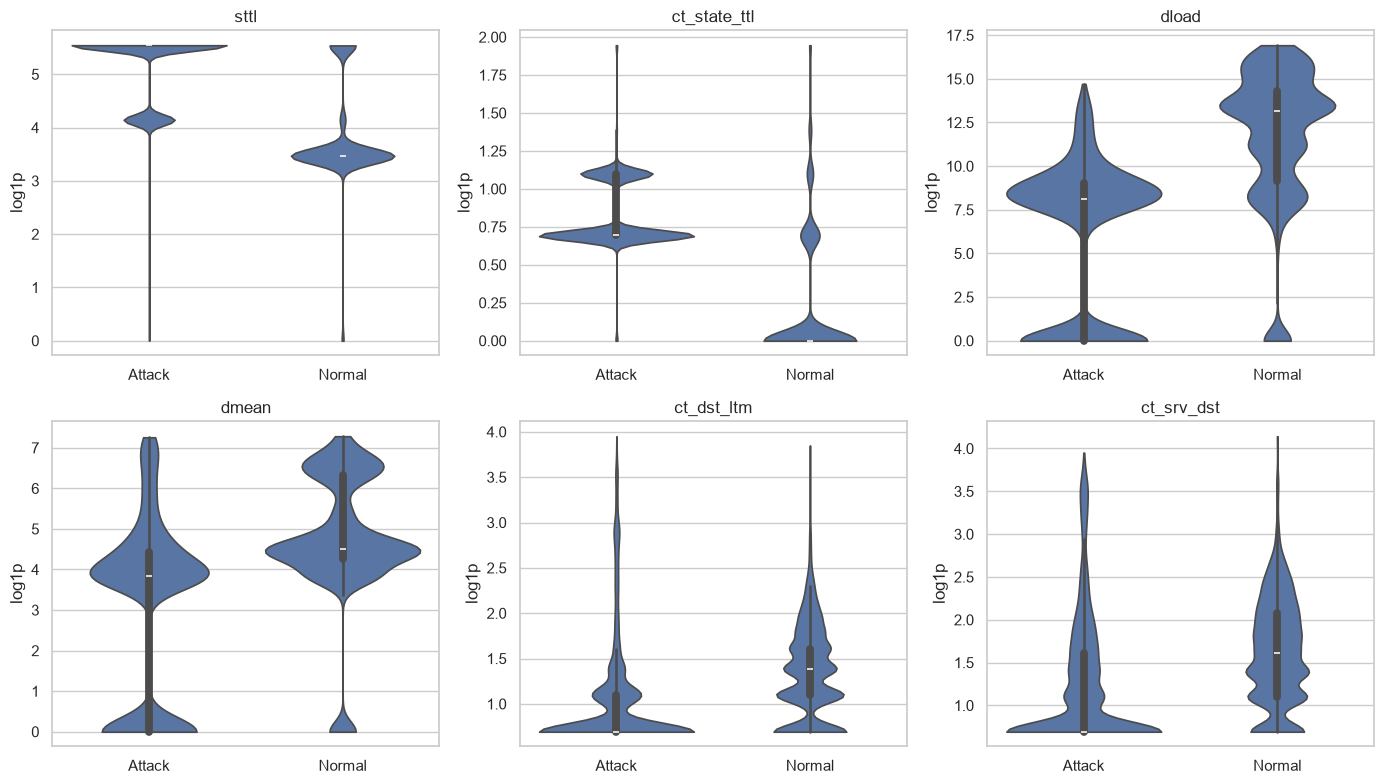

In [79]:
top6 = sep.head(6).index.tolist()
sample = train_dedup.sample(20000, random_state=RANDOM_STATE) # a sample is enough for plotting
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, top6):
    sns.violinplot(x=sample["label"].map({0: "Normal", 1: "Attack"}), y=np.log1p(sample[c]), ax=ax, cut=0)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.set_ylabel("log1p")
plt.tight_layout()
plt.savefig(FIGS / "violin_top_features.png", dpi=150)
plt.show()

The two strongest features are `sttl` (0.71) and `ct_state_ttl` (0.68), both based on TTL, which we check as a possible shortcut in Section 9. After them:
- `dload` (-0.58) and `dmean` (-0.41): attacks get much less data back (median `dload` 3,291 vs 513,866 for normal). This makes sense: scans and floods are mostly one-way and get little or no reply.
- `ct_dst_ltm` and `ct_srv_dst` (about -0.35): normal hosts make more repeated connections to the same destinations and services, as in everyday use.

---> Apart from TTL, the strongest signals match real attack behavior (one-way traffic, few replies)

**9. Shortcut check: TTL features**

TTL (time to live) values depend mostly on how many network hops a packet travelled, so in a lab they can reflect *which machine* sent the traffic rather than *what* the traffic does. If a few TTL values almost perfectly predict the label, the model might learn the lab setup instead of attack behavior.

In [80]:
for c in ["sttl", "dttl", "ct_state_ttl"]:
    print(f"\n=== {c} ===")
    print(pd.crosstab(train_dedup[c], train_dedup["label"], margins=True).sort_values("All", ascending=False).head(10))


=== sttl ===
label      0      1     All
sttl                       
All    51890  55850  107740
254     9988  42050   52038
31     39123      0   39123
62      2037  13716   15753
0        633     78     711
1         61      0      61
63        29      0      29
255        2      6       8
64         7      0       7
60         6      0       6

=== dttl ===
label      0      1     All
dttl                       
All    51890  55850  107740
252     9174  38202   47376
29     39123      0   39123
0       3518  17264   20782
60        71    384     455
31         2      0       2
254        2      0       2

=== ct_state_ttl ===
label             0      1     All
ct_state_ttl                      
All           51890  55850  107740
1              8176  37970   46146
0             39394    463   39857
2              2730  16956   19686
3               998    159    1157
6               592    302     894


To measure how strong this shortcut is, we predict the label using **only** `sttl`: for each `sttl` value, we predict the most common label.

In [81]:
majority_by_sttl = train_dedup.groupby("sttl")["label"].agg(lambda s: s.mode()[0])
pred = train_dedup["sttl"].map(majority_by_sttl)
print(f"Accuracy using ONLY sttl: {(pred == train_dedup['label']).mean():.3f}")

Accuracy using ONLY sttl: 0.888


`sttl` alone predicts the label with 88.8% accuracy. 99.8% of attacks have `sttl` = 254 or 62, while `sttl` = 31 (39,123 rows) is 0% attack and covers 75.4% of normal traffic. `dttl` and `ct_state_ttl` show the same pattern.

As a result it is reasonable to think that this is most likely a lab artifact as TTL depends on the sender's operating system and the number of hops, so it shows which machine sent the traffic (the attack generator vs normal hosts), not what the traffic does. In a real network, attackers could have any TTL.

**Why do we do this?**: We keep the TTL features for the main models, but retrain the final model without `sttl`, `dttl` and `ct_state_ttl` ---> a large drop would mean the model relies on the lab setup

**10. Correlation between numeric features**

A lot of the traffic features measure similar things, like packets and bytes. If two features are highly correlated, they mostly carry the same information, so we want to see how much of this there is.

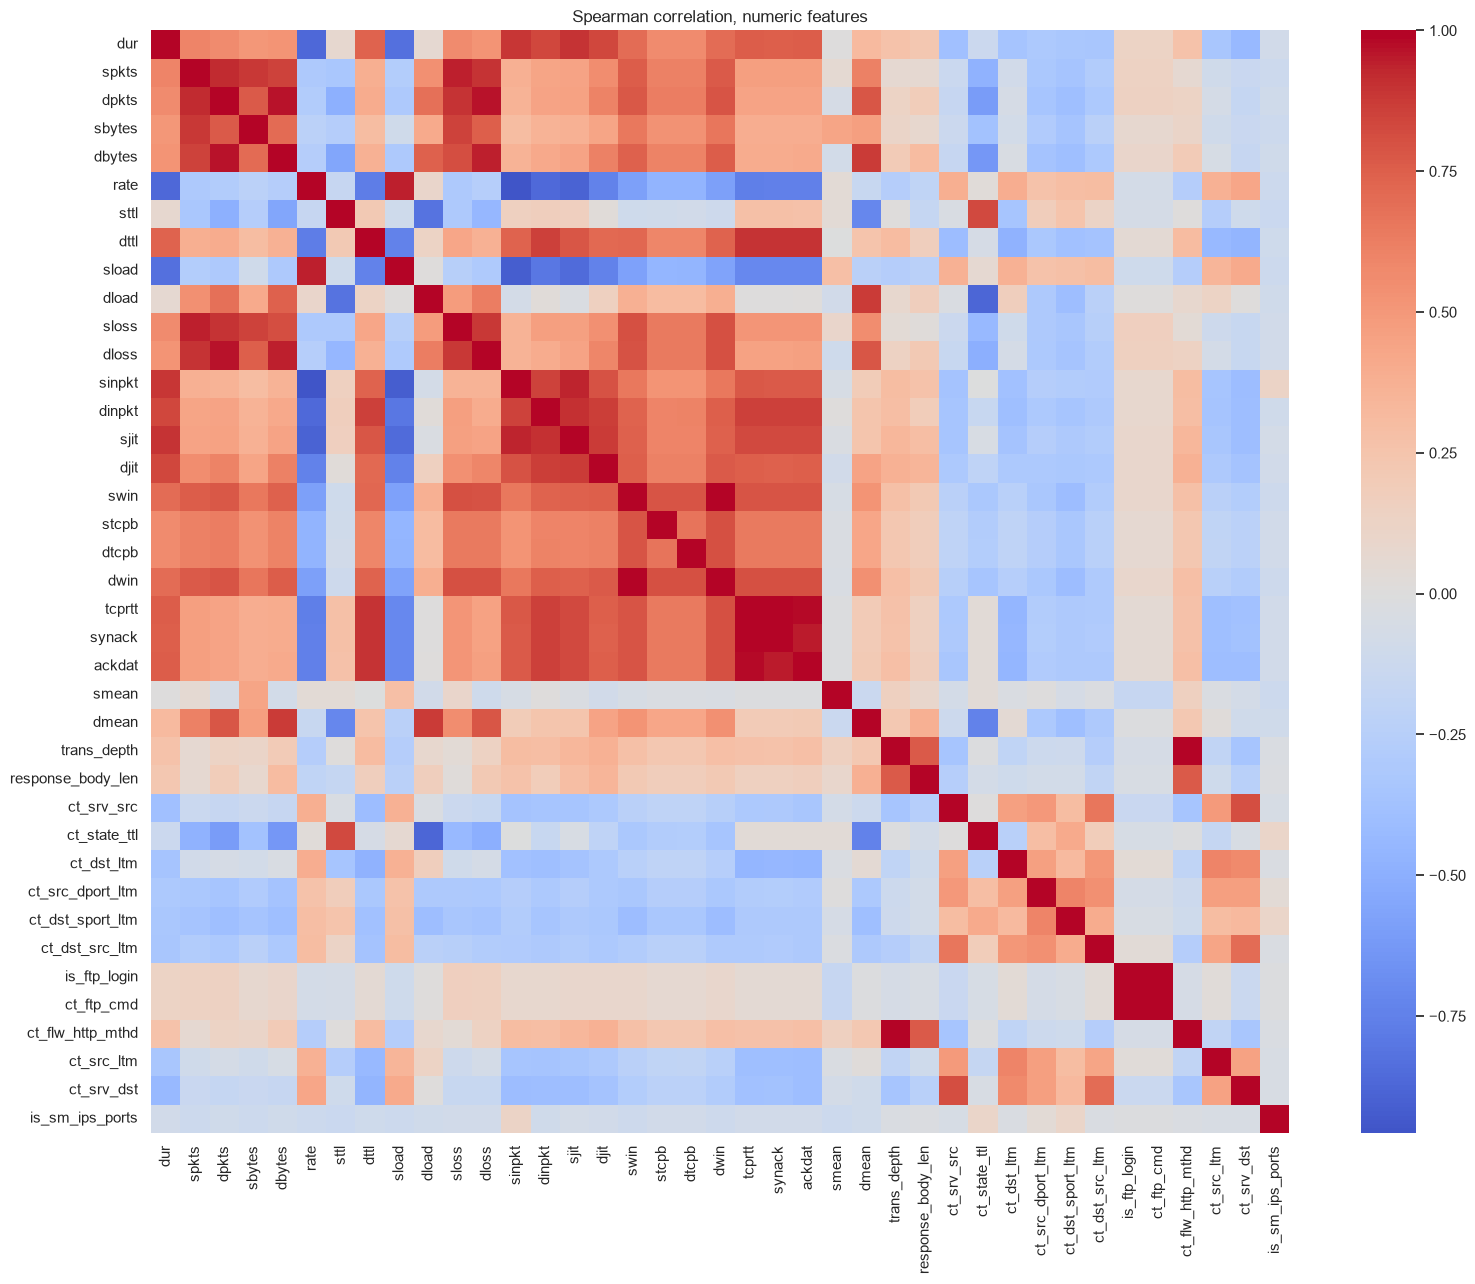

In [82]:
corr = train_dedup[num_cols].corr(method="spearman")
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation, numeric features")
plt.tight_layout()
plt.savefig(FIGS / "corr_matrix.png", dpi=150)
plt.show()

In [83]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)) # keep each pair once
pairs = upper.stack().loc[lambda s: s.abs() > 0.9].sort_values(ascending=False)
print(len(pairs), "pairs with |rho| > 0.9")
pairs

16 pairs with |rho| > 0.9


is_ftp_login  ct_ftp_cmd          1.000000
trans_depth   ct_flw_http_mthd    0.999387
tcprtt        synack              0.989996
swin          dwin                0.986858
tcprtt        ackdat              0.979783
dpkts         dbytes              0.968488
              dloss               0.962821
synack        ackdat              0.950898
dbytes        dloss               0.946375
rate          sload               0.943478
spkts         sloss               0.942665
sinpkt        sjit                0.933237
spkts         dpkts               0.921266
dinpkt        sjit                0.901180
sload         sinpkt             -0.917066
rate          sinpkt             -0.957219
dtype: float64

We found 16 pairs with a correlation above 0.9. Most of them make sense once you look at what the features mean:
- `is_ftp_login` and `ct_ftp_cmd` are exactly the same column, and `trans_depth` is almost the same as `ct_flw_http_mthd`
- packets, bytes and lost packets go together (`spkts`, `dpkts`, `dbytes`, `sloss`, `dloss`), since more packets means more bytes and more chances to lose some
- `tcprtt` is basically `synack` + `ackdat`, so these three move together
- `rate`, `sload` and `sinpkt` are all about speed: more packets per second means less time between packets
- `swin` and `dwin` are almost always the same value

We drop `is_ftp_login` since it is just a copy, and keep the rest.

**Why do we do this?**: Correlated features give the model the same information twice and can make the weights of linear models unstable ---> this is why we use L2 regularization and try PCA (T2/T3) later

**11. Summary: EDA decisions for preprocessing**

| What we found | What we do |
|---|---|
| 67,601 duplicate rows (38.6%) | Remove them before splitting train/validation |
| 229 feature vectors with both labels | Keep them, they are only a few |
| 51.8% attack after removing duplicates | No class weights, use precision/recall/F1/FPR |
| No missing values, `service = "-"` is common | Keep `-` as its own category |
| 133 `proto` values, top 15 cover 96.7% | Keep top 15, rest becomes "other" |
| Very rare `state` values (13 rows) | Group into "other" |
| 3 categorical columns | One-hot encode |
| 33 heavily skewed numeric features | `log1p` on `LOG_COLS` (31 columns) |
| `is_ftp_login` = `ct_ftp_cmd` | Drop `is_ftp_login` |
| Features on very different scales | `StandardScaler`, fit on training data only |
| `sttl` alone gets 88.8% accuracy | Keep TTL features, but test the final model without them |
| 16 highly correlated pairs | L2 regularization, PCA as one of the transformations |
| `id` and `attack_cat` | Not used as inputs, `attack_cat` only for error analysis |

**12. Additional findings: attack types for the extensive stage of the project**

This part is not used for the binary model. We only look at `attack_cat` here to understand the data better, and because it will help later when we check which attack types our model misses.

In [84]:
cats = pd.DataFrame({
    "before dedup": train["attack_cat"].value_counts(),
    "after dedup": train_dedup["attack_cat"].value_counts(),
})
cats["share removed"] = 1 - cats["after dedup"] / cats["before dedup"]
cats.sort_values("before dedup", ascending=False).round(3)

,before dedup,after dedup,share removed
attack_cat,,,
Normal,56000,51890,0.073
Generic,40000,4181,0.895
Exploits,33393,19844,0.406
Fuzzers,18184,16150,0.112
DoS,12264,3806,0.690
Reconnaissance,10491,7522,0.283
Analysis,2000,1594,0.203
Backdoor,1746,1535,0.121
Shellcode,1133,1091,0.037


We also check which attack types show up in the 229 feature vectors that have both labels, meaning these attacks look exactly like normal traffic.

In [85]:
key = list(features_only.columns)
both = conflict[conflict > 1].index
train.set_index(key).loc[both, "attack_cat"].value_counts()

attack_cat
Fuzzers      543
Normal       396
Shellcode      1
Name: count, dtype: int64

Most of the duplicates came from just a few attack types. Generic lost almost 90% of its rows (from 40,000 to 4,181), DoS lost 69% and Exploits lost 41%, while rare ones like Worms and Shellcode barely changed. So after removing duplicates, Generic is not one of the biggest attack types anymore.

The 229 conflicting vectors are almost all Fuzzers and Normal (543 Fuzzers rows, 396 Normal rows and 1 Shellcode). Fuzzers send random or broken inputs to a service, which at the flow level can look a lot like normal traffic ---> we expect Fuzzers to be one of the attacks our model misses the most.